Same training setup as `baseline_training.ipynb`, with one change: the target is **log price per square foot**, `log(sold_price / square_feet)`.

Cross-validation MdAPE is still a percentage error on price, because the square footage cancels in the ratio. The final validation scores and residual plots use sale prices in dollars, reconstructed as `exp(prediction) * square_feet`.

In [14]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import optuna
import sys
from pathlib import Path
import torch # Torch needs to be installed manually if you want cuda. See installation command on pytorch website
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-06-01")    # sales on or after this date are validation
N_TRIALS = 10                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
K_FOLDS = 5                              # time series cross validation folds
DEBUG = True                             # print MdAPE and MAPE for every fold

In [16]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [17]:
from baseline_features import (
    list_aware_features,
    make_price_per_sqft,
    off_market_features,
    square_feet,
)

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

# Price per square foot is undefined when area is missing or zero.
train = train[square_feet(train["house_area"]) > 0]
val = val[square_feet(val["house_area"]) > 0]

X_train = make_features(train)
X_val = make_features(val)

y_train = np.log(make_price_per_sqft(train))
y_val = np.log(make_price_per_sqft(val))
sqft_val = square_feet(val["house_area"])

print(f"Features: {X_train.columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['house_area_was_range', 'square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'municipality', 'community', 'house_type', 'house_style', 'month', 'year', 'day', 'is_apartment', 'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1', 'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1', 'is_apartment_x_washrooms_0', 'is_apartment_x_washrooms_1', 'is_apartment_x_parking_0', 'is_apartment_x_parking_1', 'square_feet_x_bedrooms', 'square_feet_x_washrooms', 'square_feet_x_parking', 'bedrooms_x_washrooms', 'bedrooms_x_parking', 'washrooms_x_parking']
train: 127,762 sales up to 2025-06-01
val:   22,238 sales from 2025-06-01


In [18]:
def mdape(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

loss = mdape

In [19]:
from sklearn.model_selection import TimeSeriesSplit


def cross_val(X, y, params, K=5, debug=False, validation_loss=mdape):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    X and y must be sorted by time (listings is sorted by date_sold).
    Returns the mean validation loss over the folds."""
    mdape_scores = []
    mape_scores = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(X), start=1):
        X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

        model = XGBRegressor(**params, device=DEVICE, n_estimators=N_ESTIMATORS,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=SEED)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        pred = model.predict(X_va)
        mdape_scores.append(validation_loss(y_va, pred))

        mape_scores.append(np.mean(100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)))

        if debug:
            error = 100 * np.abs(np.exp(pred) / np.exp(y_va) - 1)
            print(f"fold {fold}: train {len(train_idx):,}  val {len(val_idx):,}  "
                  f"MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores)

In [20]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, validation_loss=loss)
    return score

In [21]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="log price per sqft")
study.optimize(objective, n_trials=N_TRIALS)

print("best val MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)

[I 2026-10-16 16:58:14,956] A new study created in memory with name: log price per sqft


fold 1: train 21,297  val 21,293  MdAPE 10.36%  MAPE 12.84%
fold 2: train 42,590  val 21,293  MdAPE 10.82%  MAPE 13.30%
fold 3: train 63,883  val 21,293  MdAPE 10.02%  MAPE 12.45%
fold 4: train 85,176  val 21,293  MdAPE 10.16%  MAPE 13.09%
fold 5: train 106,469  val 21,293  MdAPE 10.24%  MAPE 13.16%
mean MdAPE 10.32%  mean MAPE 12.97%


[I 2026-10-16 16:58:30,555] Trial 0 finished with value: 10.321691703660347 and parameters: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.9, 'colsample_bytree': 0.5, 'max_bin': 1778, 'min_child_weight': 10, 'gamma': 0.1, 'lambda': 7.103714746188992, 'alpha': 0.0013187949354214168, 'max_delta_step': 1}. Best is trial 0 with value: 10.321691703660347.


fold 1: train 21,297  val 21,293  MdAPE 10.51%  MAPE 12.95%
fold 2: train 42,590  val 21,293  MdAPE 11.10%  MAPE 13.73%
fold 3: train 63,883  val 21,293  MdAPE 10.75%  MAPE 13.40%
fold 4: train 85,176  val 21,293  MdAPE 10.57%  MAPE 13.60%
fold 5: train 106,469  val 21,293  MdAPE 10.22%  MAPE 13.02%
mean MdAPE 10.63%  mean MAPE 13.34%


[I 2026-10-16 16:58:37,179] Trial 1 finished with value: 10.630434882068831 and parameters: {'learning_rate': 0.09, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'max_bin': 808, 'min_child_weight': 3, 'gamma': 0.08, 'lambda': 4.791227993546376, 'alpha': 0.0058203973119644765, 'max_delta_step': 9}. Best is trial 0 with value: 10.321691703660347.


...

fold 1: train 21,297  val 21,293  MdAPE 10.29%  MAPE 12.80%
fold 2: train 42,590  val 21,293  MdAPE 10.59%  MAPE 13.32%
fold 3: train 63,883  val 21,293  MdAPE 10.04%  MAPE 12.61%
fold 4: train 85,176  val 21,293  MdAPE 10.03%  MAPE 13.12%
fold 5: train 106,469  val 21,293  MdAPE 9.76%  MAPE 12.67%
mean MdAPE 10.14%  mean MAPE 12.90%


[I 2026-10-16 17:01:32,276] Trial 8 finished with value: 10.144390469592507 and parameters: {'learning_rate': 0.02, 'max_depth': 7, 'subsample': 0.4, 'colsample_bytree': 0.8, 'max_bin': 325, 'min_child_weight': 1, 'gamma': 0.01, 'lambda': 9.311413198108736, 'alpha': 0.030559905399179667, 'max_delta_step': 8}. Best is trial 8 with value: 10.144390469592507.


fold 1: train 21,297  val 21,293  MdAPE 10.62%  MAPE 13.10%
fold 2: train 42,590  val 21,293  MdAPE 11.39%  MAPE 13.88%
fold 3: train 63,883  val 21,293  MdAPE 10.57%  MAPE 13.18%
fold 4: train 85,176  val 21,293  MdAPE 10.41%  MAPE 13.39%
fold 5: train 106,469  val 21,293  MdAPE 10.37%  MAPE 13.24%
mean MdAPE 10.67%  mean MAPE 13.36%


[I 2026-10-16 17:01:36,674] Trial 9 finished with value: 10.671080451758971 and parameters: {'learning_rate': 0.09999999999999999, 'max_depth': 7, 'subsample': 1.0, 'colsample_bytree': 0.6, 'max_bin': 1331, 'min_child_weight': 4, 'gamma': 0.09, 'lambda': 2.1227964272241358, 'alpha': 0.11463214978336936, 'max_delta_step': 6}. Best is trial 8 with value: 10.144390469592507.


best val MdAPE: 10.14
best params: {'learning_rate': 0.02, 'max_depth': 7, 'subsample': 0.4, 'colsample_bytree': 0.8, 'max_bin': 325, 'min_child_weight': 1, 'gamma': 0.01, 'lambda': 9.311413198108736, 'alpha': 0.030559905399179667, 'max_delta_step': 8}


In [22]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

max_bin: 0.3582
lambda: 0.1541
alpha: 0.1500
min_child_weight: 0.0728
learning_rate: 0.0666
gamma: 0.0533
subsample: 0.0527
max_delta_step: 0.0438
colsample_bytree: 0.0251
max_depth: 0.0234


In [23]:
model = XGBRegressor(**study.best_params,
                     enable_categorical=True,
                     device=DEVICE,
                     early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                     n_estimators=N_ESTIMATORS,
                     random_state=SEED)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

predicted = np.exp(model.predict(X_val)) * sqft_val
error = 100 * np.abs(predicted / val["sold_price"] - 1)
print(f"{TRACK}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

off_market  MdAPE 10.16%  MAPE 13.21%


In [24]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)

community                       0.118265
is_apartment_x_square_feet_1    0.111003
house_type                      0.086828
square_feet                     0.072258
is_apartment_x_square_feet_0    0.065775
washrooms                       0.061202
is_apartment                    0.044624
is_apartment_x_bedrooms_1       0.043443
is_apartment_x_washrooms_0      0.038725
washrooms_x_parking             0.033110
is_apartment_x_parking_1        0.026364
is_apartment_x_washrooms_1      0.026364
square_feet_x_bedrooms          0.024257
lot_front                       0.023393
municipality                    0.019051
day                             0.018985
house_style                     0.016174
lot_depth                       0.014368
latitude                        0.014272
parking                         0.013979
square_feet_x_washrooms         0.013975
longitude                       0.013251
year                            0.013128
month                           0.012884
bedrooms_x_washr

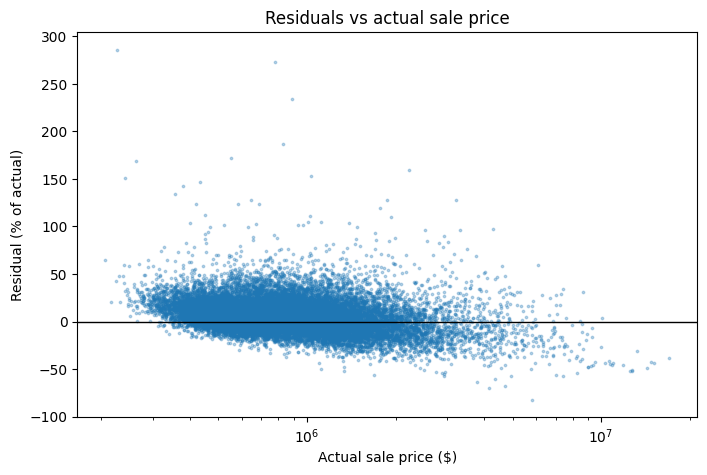

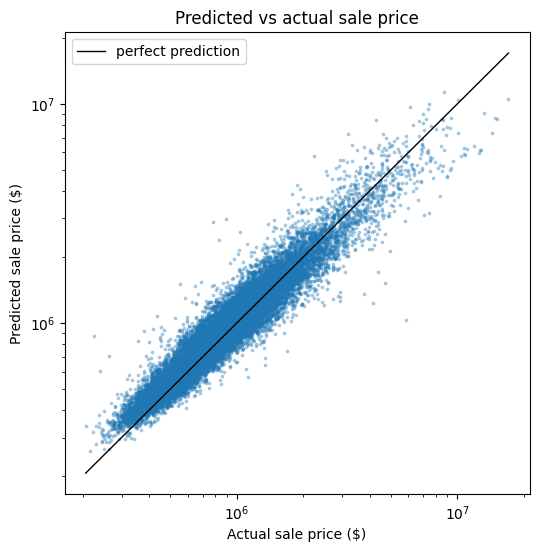

In [25]:
import diagnostics

actual = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)

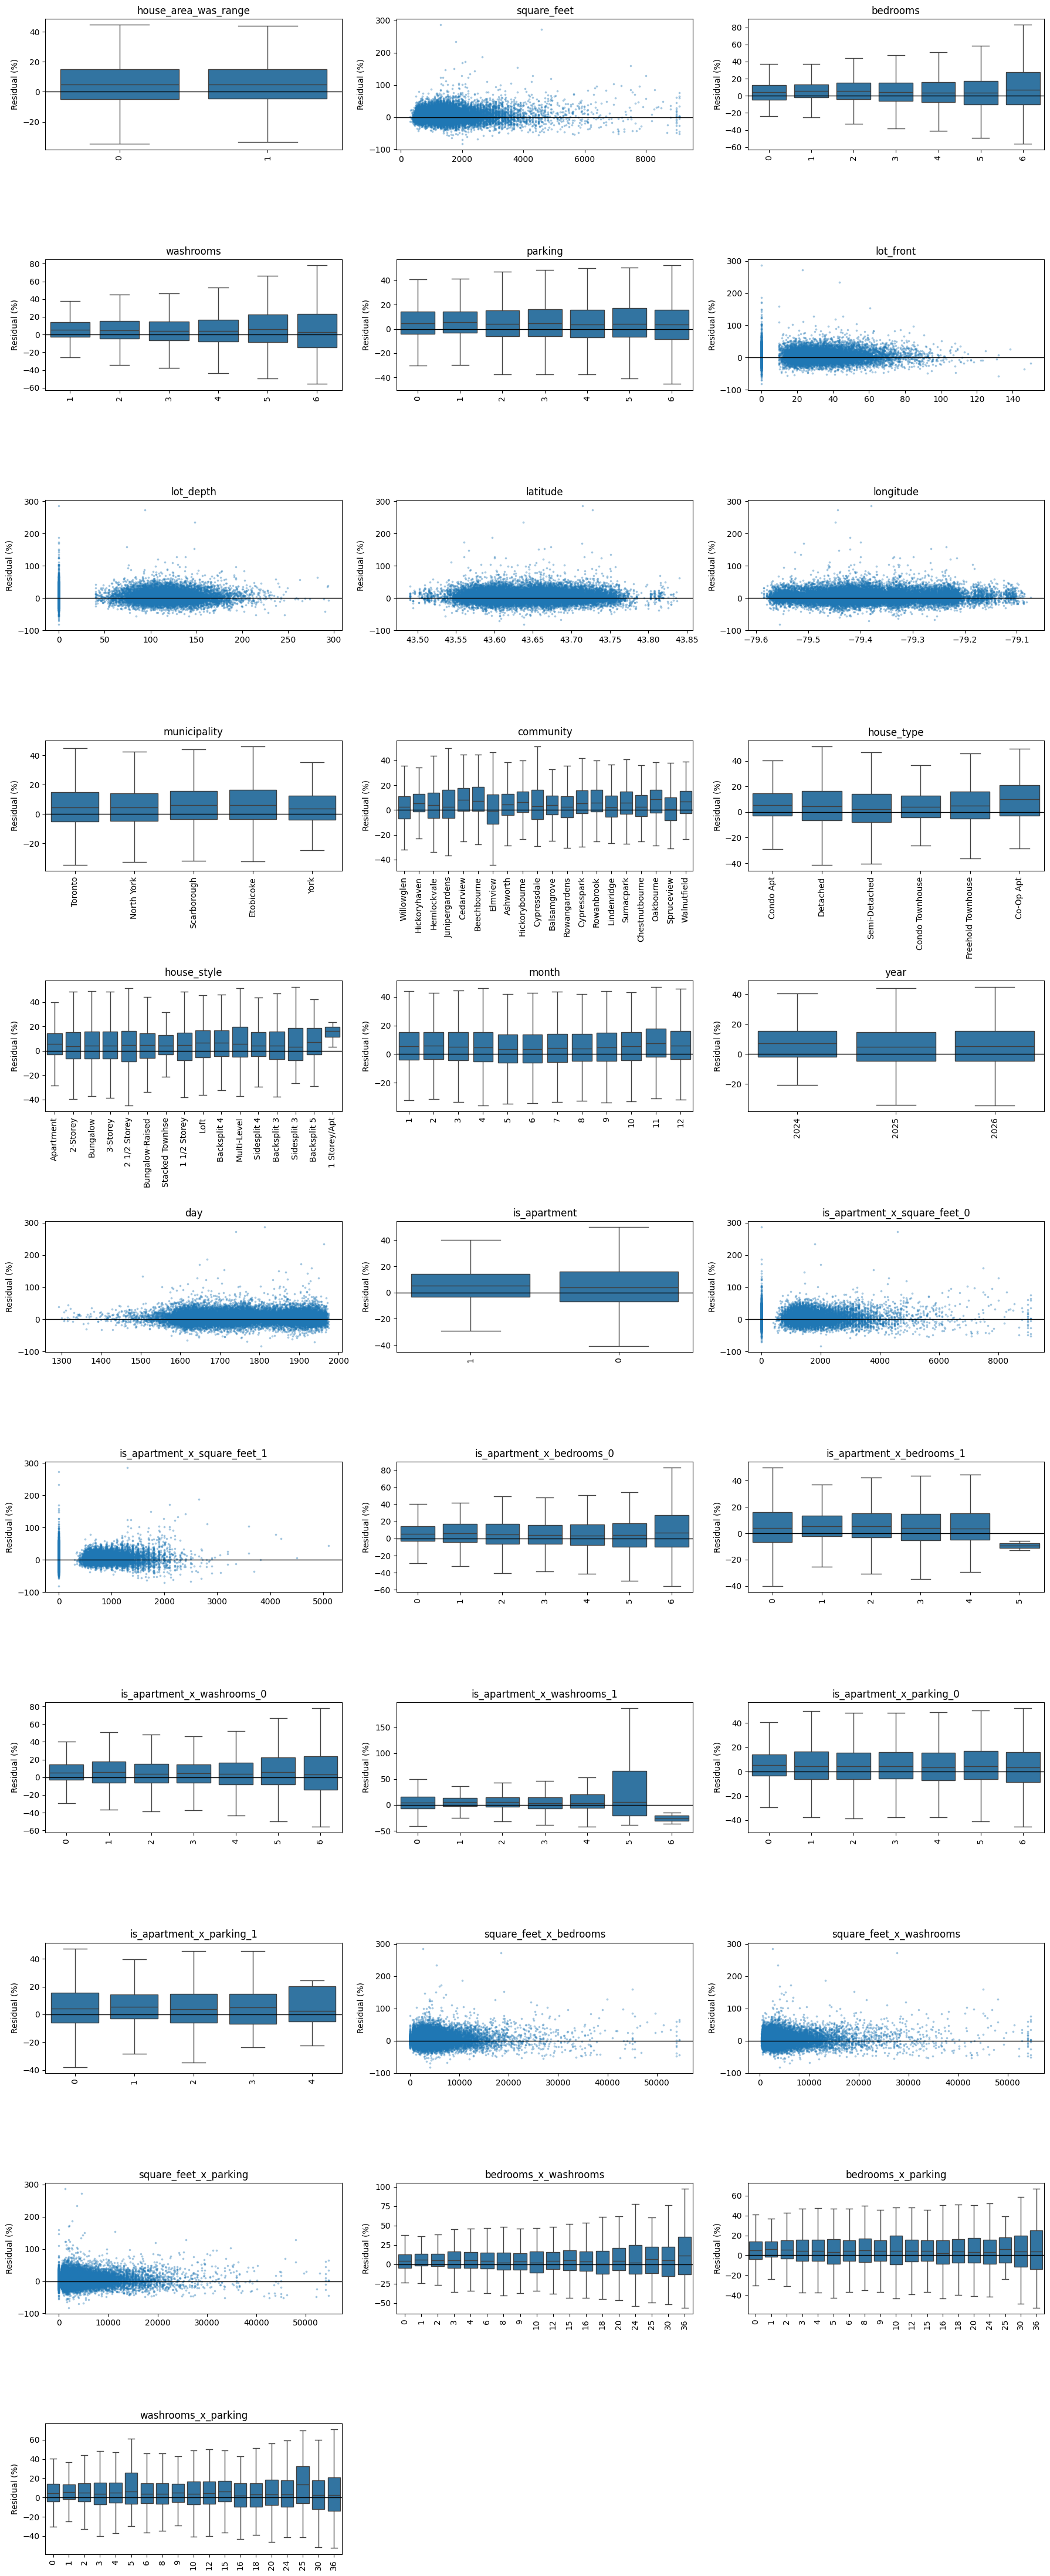

In [26]:
diagnostics.plot_residuals_by_feature(X_val, actual, predicted)